In [ ]:
#Write library routine for Runge-Kutta-4. Make sure you can call / use the same RK4 subroutine for both first and second order ODE.

def rk4_step(f, x, y, h):
    
    # k1
    d1 = f(x, y)
    k1 = [h * d for d in d1]
    
    # k2
    y2 = [y[i] + 0.5 * k1[i] for i in range(len(y))]
    d2 = f(x + 0.5 * h, y2)
    k2 = [h * d for d in d2]
    
    # k3
    y3 = [y[i] + 0.5 * k2[i] for i in range(len(y))]
    d3 = f(x + 0.5 * h, y3)
    k3 = [h * d for d in d3]
    
    # k4
    y4 = [y[i] + k3[i] for i in range(len(y))]
    d4 = f(x + h, y4)
    k4 = [h * d for d in d4]
    
    # Update next state
    y_next = [y[i] + (k1[i] + 2*k2[i] + 2*k3[i] + k4[i]) / 6.0 for i in range(len(y))]
    return y_next

def rk4_solve(f, x0, y0, x_end, h):
    x_list = [x0]
    y_list = [y0]
    
    x = x0
    y = y0
    
    steps = int(round((x_end - x0) / h))
    for _ in range(steps):
        y = rk4_step(f, x, y, h)
        x = x + h
        x_list.append(x)
        y_list.append(y)
        
    return x_list, y_list


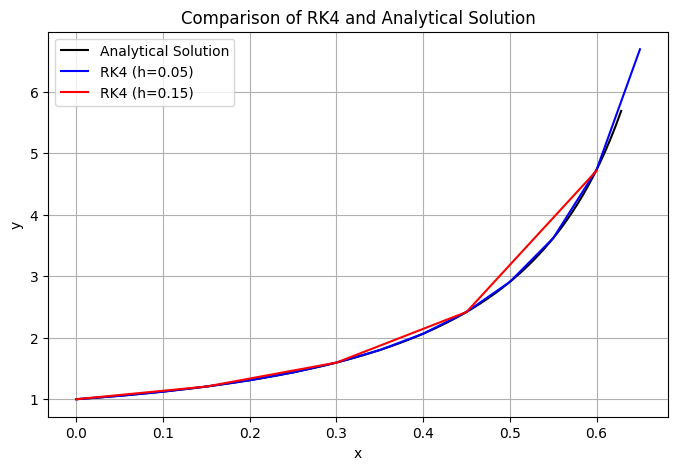

In [ ]:
#Use Runge-Kutta-4 method to solve and the following differential equation and compare with analytical form over the range x ∈ [0, π/5]. Use step sizes 0.05, 0.15.
import math
import matplotlib.pyplot as plt
import library

def f2(x, y):
    return [(x + y[0])**2]

def y(x):
    return math.tan(x + math.pi / 4) - x


# Solve using RK4 for both step sizes
x_05, y_05 = library.rk4_solve(f2, 0.0, [1.0], math.pi / 5, 0.05)
x_15, y_15 = library.rk4_solve(f2, 0.0, [1.0], math.pi / 5, 0.15)


x_fine = [i * (math.pi / 5 / 200) for i in range(201)]
y_fine = [y(x) for x in x_fine]

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(x_fine, y_fine, label='Analytical Solution', color='black', linewidth=1.5)
plt.plot(x_05, [y[0] for y in y_05], color = 'blue', label='RK4 (h=0.05)', markersize=5)
plt.plot(x_15, [y[0] for y in y_15], color = 'red', label='RK4 (h=0.15)', markersize=5)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Comparison of RK4 and Analytical Solution')
plt.legend()
plt.grid(True)
plt.show()

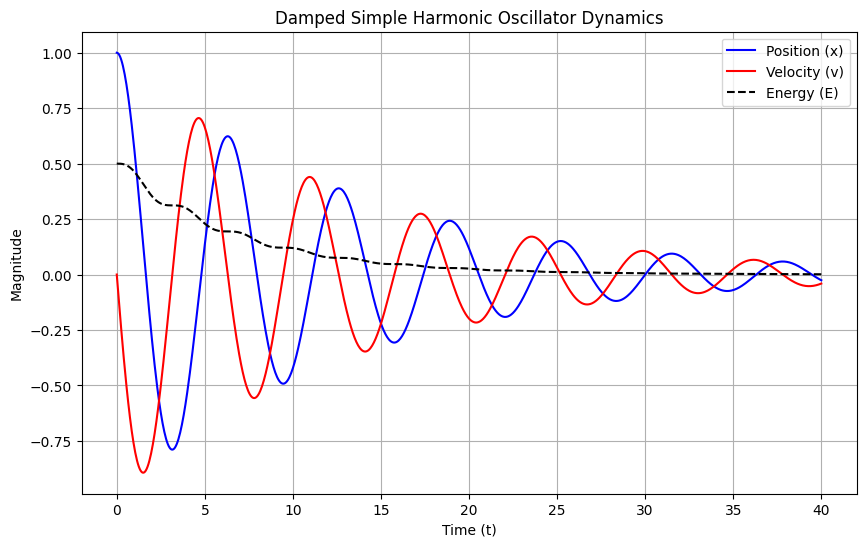

In [4]:
#Use RK4 to solve the damped simple harmonic oscillator using the following initial values and parameters over a time range [0, 40]. Plot variation of x, v andtotal energy E with time t.
import library
import matplotlib.pyplot as plt

def f3(t, y):
    x, v = y[0], y[1]
    
    dxdt = v
    dvdt = -0.15 * v - 1.0 * x
    return [dxdt, dvdt]

t_list, y_list = library.rk4_solve(f3, 0.0, [1.0, 0.0], 40.0, 0.05)

x_vals = [state[0] for state in y_list]
v_vals = [state[1] for state in y_list]
E_vals = [0.5 * (x**2 + v**2) for x, v in zip(x_vals, v_vals)]

plt.figure(figsize=(10, 6))
plt.plot(t_list, x_vals, label='Position (x)', color='blue')
plt.plot(t_list, v_vals, label='Velocity (v)', color='red')
plt.plot(t_list, E_vals, label='Energy (E)', color='Black', linestyle='--')
plt.xlabel('Time (t)')
plt.ylabel('Magnitude')
plt.title('Damped Simple Harmonic Oscillator Dynamics')
plt.legend()
plt.grid(True)
plt.show()


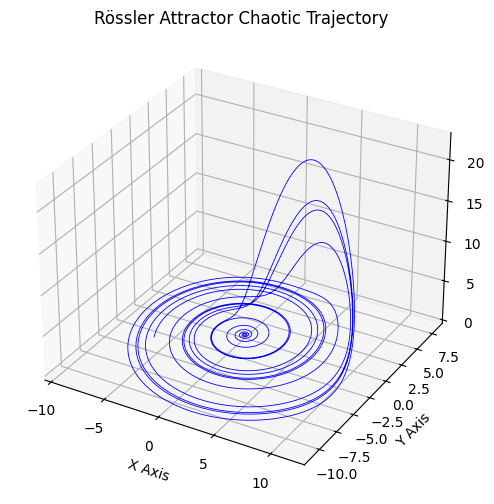

In [ ]:
#Solve the R ̈ossler system for a = 0.2, b = 0.2, c = 5.7 and show a 3-dim (x, y, z)plot.

import library

def f4(t, y):
    x, y_val, z = y[0], y[1], y[2]
    a, b, c = 0.2, 0.2, 5.7
    
    dxdt = -y_val - z
    dydt = x + a * y_val
    dzdt = b + z * (x - c)
    return [dxdt, dydt, dzdt]

t_rossler, y_rossler = library.rk4_solve(f4, 0.0, [0.1, 0.0, 0.1], 100.0, 0.01)

x_r = [y[0] for y in y_rossler]
y_r = [y[1] for y in y_rossler]
z_r = [y[2] for y in y_rossler]

# 3D Plotting
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x_r, y_r, z_r, lw=0.6, color='blue')
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')
ax.set_title('Rössler Attractor Chaotic Trajectory')
plt.show()
